In [1]:
# Penguins — Feature engineering and modeling

## Notebook conventions

## This notebook reproduces the original analysis but explicitly documents the
## **feature engineering** that in the original script was done by trial and
## error without leaving any trace.

## Every cell follows this pattern:

## 1. **Comments** with the reasoning (why it is done).
## 2. **Code** with the implementation (what is done).

### Inventory of `penguins` variables

## | Variable | Original type | Modeling role | Transformation applied |
## |---|---|---|---|
## | `species` | categorical (3 levels) | **target** in classification · feature in regression | ordinal encoding (`Adelie=1, Chinstrap=2, Gentoo=3`) |
## | `island` | categorical (3 levels) | *dropped* (redundant with `species`) | — |
## | `bill_length_mm` | continuous numeric | feature | Min-Max to `[0, 1]` |
## | `bill_depth_mm` | continuous numeric | feature | Min-Max to `[0, 1]` |
## | `flipper_length_mm` | continuous numeric | feature | Min-Max to `[0, 1]` |
## | `body_mass_g` | continuous numeric | feature in classification · **target** in regression | Min-Max to `[0, 1]` (only when used as feature) |
## | `sex` | categorical (2 levels) | feature | binary encoding (`Male=0, Female=1`) |

### Feature engineering decisions (justification)

## - **`island` is dropped**: highly correlated with `species` (every Gentoo
##   lives in Biscoe, Chinstrap in Dream). Including it in classification would
##   cause *leakage*; in regression it adds nothing over `species`.
## - **`species` is used as a feature in regression**: even though it looks
##   circular, the original notebook did it this way and it is **kept** to
##   preserve results; conceptually it acts as a *proxy* for body size
##   (Gentoo > Chinstrap > Adelie).
## - **Min-Max instead of StandardScaler**: the linear models in the notebook
##   (LogisticRegression, LinearRegression) and the tree do not require scaling,
##   but Min-Max preserves the original distribution shape and was the
##   empirical choice in the original script.

from __future__ import annotations

import logging
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
)
logger = logging.getLogger("penguins")

# --- Reproducibility --------------------------------------------------------
RANDOM_STATE: Final[int] = 42
SPLIT_SEED_TRAIN_B: Final[int] = 7   # Seed for the disjoint train_B subset.
TEST_SIZE: Final[float] = 0.20
LOGREG_MAX_ITER: Final[int] = 1000
CV_FOLDS: Final[int] = 5

# --- Encoding maps (feature engineering) ------------------------------------
SPECIES_MAP: Final[dict[str, int]] = {"Adelie": 1, "Chinstrap": 2, "Gentoo": 3}
SEX_MAP: Final[dict[str, int]] = {"Male": 0, "Female": 1}

# --- Explicit role of each variable -----------------------------------------
RAW_NUMERIC_FEATURES: Final[tuple[str, ...]] = (
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
)
PHYSICAL_FEATURES: Final[tuple[str, ...]] = RAW_NUMERIC_FEATURES

STUDY_CONFIGS: Final[dict[str, tuple[str, ...]]] = {
    "physical_only": PHYSICAL_FEATURES,
    "physical_plus_sex": (*PHYSICAL_FEATURES, "sex"),
}
SPECIES_LABELS: Final[tuple[str, ...]] = ("Adelie", "Chinstrap", "Gentoo")

In [2]:
## Load the dataset

## `penguins` is loaded from seaborn (official source, no local CSV). No
## transformation yet: this cell is pure **I/O** so the raw data can be audited
## before any feature engineering decision.

raw: pd.DataFrame = sns.load_dataset("penguins")
logger.info("Dataset shape: %d rows x %d columns", *raw.shape)
print(raw.head())

2026-10-09 22:32:01,107 | INFO     | Dataset shape: 344 rows x 7 columns


  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


In [3]:
## Structural inspection of the dataset

## Before touching anything, we audit:

## - **Dimensions** (rows × columns).
## - **Data types** per column → decides which variables accept Min-Max and
##   which ones require encoding.
## - **Null values** per column → input for the cleaning step in the next cell.

## This cell **does not modify** the DataFrame: it is purely diagnostic.

n_rows, n_cols = raw.shape
logger.info("Rows: %d | Columns: %d", n_rows, n_cols)

logger.info("Data types per column:\n%s", raw.dtypes.to_string())

nan_per_col = raw.isna().sum()
logger.info("Null values per column:\n%s", nan_per_col.to_string())
logger.info(
    "Rows with at least one NaN: %d (%.2f %%)",
    int(raw.isna().any(axis=1).sum()),
    100 * raw.isna().any(axis=1).mean(),
)

2026-10-09 22:32:01,217 | INFO     | Rows: 344 | Columns: 7
2026-10-09 22:32:01,228 | INFO     | Data types per column:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
2026-10-09 22:32:01,237 | INFO     | Null values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
2026-10-09 22:32:01,247 | INFO     | Rows with at least one NaN: 11 (3.20 %)


In [4]:
# --- Cell: Missing-value cleaning -------------------------------------------
# The raw dataset contains rows with at least one NaN (mostly `sex` in a few
# records and some numeric entries). The original notebook drops them all
# with `dropna(axis=0)` because the missing rate is small (< 4 %) and
# imputation would add noise to variables that are already strongly
# correlated. We keep that decision to preserve numerical results.
#
# `reset_index(drop=True)` is added so downstream positional slicing does
# not carry the original row labels, which avoids subtle indexing bugs.
n_before = len(raw)
clean: pd.DataFrame = raw.dropna(axis=0).reset_index(drop=True)
n_after = len(clean)

logger.info(
    "Dropped %d rows with NaN (%.2f %% of the dataset). Remaining: %d rows.",
    n_before - n_after,
    100 * (n_before - n_after) / n_before,
    n_after,
)
print(clean.head())

2026-10-09 22:32:01,339 | INFO     | Dropped 11 rows with NaN (3.20 % of the dataset). Remaining: 333 rows.


  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen            36.7           19.3              193.0   
4  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3       3450.0  Female  
4       3650.0    Male  


In [5]:
# --- Cell: Categorical encoding (feature engineering) -----------------------
# `species` and `sex` are the only categorical columns kept in the pipeline.
# Both are encoded with ordinal mappings declared centrally in the constants
# section, so the transformation is auditable and reversible:
#
#     species:  Adelie -> 1, Chinstrap -> 2, Gentoo -> 3
#     sex:      Male   -> 0, Female    -> 1
#
# Notes on the choice:
# - Ordinal (not one-hot) because the original notebook used it and we want
#   to preserve numerical results. The species order (Adelie < Chinstrap <
#   Gentoo) is not a natural order, but it correlates with body size, which
#   is fine for tree-based models and acceptable for the linear ones as a
#   first pass.
# - `island` is intentionally NOT encoded here: it is dropped at feature
#   selection (see DROPPED_FEATURES in the constants cell).
# - We operate on a copy so `clean` remains available for audit/reference.
encoded: pd.DataFrame = clean.copy()
encoded["species"] = encoded["species"].map(SPECIES_MAP).astype(int)
encoded["sex"] = encoded["sex"].map(SEX_MAP).astype(int)

logger.info("Encoded species codes: %s", sorted(encoded["species"].unique()))
logger.info("Encoded sex codes:     %s", sorted(encoded["sex"].unique()))
print(encoded.head())

2026-10-09 22:32:01,453 | INFO     | Encoded species codes: [np.int64(1), np.int64(2), np.int64(3)]
2026-10-09 22:32:01,469 | INFO     | Encoded sex codes:     [np.int64(0), np.int64(1)]


   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0        1  Torgersen            39.1           18.7              181.0   
1        1  Torgersen            39.5           17.4              186.0   
2        1  Torgersen            40.3           18.0              195.0   
3        1  Torgersen            36.7           19.3              193.0   
4        1  Torgersen            39.3           20.6              190.0   

   body_mass_g  sex  
0       3750.0    0  
1       3800.0    1  
2       3250.0    1  
3       3450.0    1  
4       3650.0    0  


In [6]:
# --- Cell: Post-encoding verification ---------------------------------------
# Sanity checks after cleaning and encoding:
#   1. No NaN must remain in the encoded frame.
#   2. `species` and `sex` must be integer dtypes.
#   3. Encoded values must be a subset of the declared map values.
#   4. `island` must still be present here; we only drop it at feature
#      selection, so we confirm nothing was lost unexpectedly.
#
# These checks are cheap and prevent silent bugs, e.g. a category renamed
# in a future seaborn release would map to NaN without raising any error.
assert encoded[["species", "sex"]].isna().sum().sum() == 0, (
    "Encoding introduced NaN — a category is missing from the maps."
)
assert encoded["species"].dtype.kind == "i", "`species` must be integer."
assert encoded["sex"].dtype.kind == "i", "`sex` must be integer."
assert set(encoded["species"].unique()) <= set(SPECIES_MAP.values())
assert set(encoded["sex"].unique()) <= set(SEX_MAP.values())
assert "island" in encoded.columns, "`island` should still be present here."

logger.info("Post-encoding checks passed.")
logger.info("Final column dtypes:\n%s", encoded.dtypes.to_string())

2026-10-09 22:32:01,898 | INFO     | Post-encoding checks passed.
2026-10-09 22:32:01,903 | INFO     | Final column dtypes:
species                int64
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                    int64


In [7]:
# --- Cell: Min-Max scaling of numeric features ------------------------------
# Only the four physical traits are scaled. `sex` and `species` are integer
# codes, not magnitudes, so scaling them would be meaningless (and would
# break the interpretation of the linear coefficients).
#
# Why Min-Max and not StandardScaler:
# - It preserves the original shape of each distribution (no assumption of
#   normality).
# - It is the scaler used in the original notebook, so results are preserved.
# - For tree-based models the choice does not matter, but for the linear
#   models it keeps coefficients comparable across features.
#
# The scaler is fitted ONCE on the full cleaned+encoded frame and reused for
# every configuration of the study. This avoids re-fitting per configuration
# and guarantees that the two study branches see the exact same scale.
scaler: MinMaxScaler = MinMaxScaler()
scaled: pd.DataFrame = encoded.copy()
scaled.loc[:, PHYSICAL_FEATURES] = scaler.fit_transform(
    scaled.loc[:, PHYSICAL_FEATURES]
)

logger.info(
    "Min-Max scaling fitted on columns: %s",
    list(PHYSICAL_FEATURES),
)
print(scaled.head())

2026-10-09 22:32:02,101 | INFO     | Min-Max scaling fitted on columns: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0        1  Torgersen        0.254545       0.666667           0.152542   
1        1  Torgersen        0.269091       0.511905           0.237288   
2        1  Torgersen        0.298182       0.583333           0.389831   
3        1  Torgersen        0.167273       0.738095           0.355932   
4        1  Torgersen        0.261818       0.892857           0.305085   

   body_mass_g  sex  
0     0.291667    0  
1     0.305556    1  
2     0.152778    1  
3     0.208333    1  
4     0.263889    0  


In [8]:
# --- Cell: Feature selection -------------------------------------------------
# Two feature sets are compared throughout the notebook:
#   - "physical_only"     : the four physical traits.
#   - "physical_plus_sex" : the same four traits plus `sex`.
# The study measures the marginal contribution of `sex` over physical traits.
#
# `island` is excluded by design and was never used in the original notebook:
# it is not an individual physical trait, and each species is strongly tied
# to specific islands, so it would act as a proxy for the target rather than
# provide an independent physical signal.
#
# The feature sets themselves are declared once in the constants cell
# (`STUDY_CONFIGS`) so every downstream step reads them from a single source.

logger.info("Feature sets under study:")
for name, features in STUDY_CONFIGS.items():
    logger.info("  %-20s -> %s", name, list(features))

assert set(STUDY_CONFIGS["physical_plus_sex"]) - set(
    STUDY_CONFIGS["physical_only"]
) == {"sex"}, "The two configurations must differ exactly by `sex`."
assert set(PHYSICAL_FEATURES) <= set(scaled.columns), (
    "All physical features must be present in the scaled frame."
)

2026-10-09 22:32:02,216 | INFO     | Feature sets under study:
2026-10-09 22:32:02,219 | INFO     |   physical_only        -> ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
2026-10-09 22:32:02,225 | INFO     |   physical_plus_sex    -> ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [9]:
# --- Cell: Master train/test split (shared across study configurations) -----
# The split is performed ONCE, by row index, on the encoded+scaled frame.
# This guarantees that both study branches ("physical_only" and
# "physical_plus_sex") see exactly the same rows in train and in test, so
# the only thing that changes between them is the FEATURE SET.
#
# Why by index and not by DataFrame:
# - It lets us materialize each configuration by selecting columns only,
#   without re-splitting and risking a different random partition.
# - It makes the "same test set across configs" invariant explicit and
#   auditable in the code.
#
# Stratification by `species` keeps class proportions stable in train and
# test; this matters for the weighted precision used downstream and for the
# per-class interpretation of the confusion matrix.

from dataclasses import dataclass
from typing import Sequence

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split


@dataclass(frozen=True)
class IndexSplit:
    """Row-index based train/test split, reusable across feature configs."""
    train_idx: np.ndarray
    test_idx: np.ndarray
    target: str


def make_index_split(
    df: pd.DataFrame,
    target: str,
    test_size: float = TEST_SIZE,
    random_state: int = RANDOM_STATE,
) -> IndexSplit:
    """Split row indices into train/test, stratified by `target`."""
    idx = np.arange(len(df))
    strat = df[target].to_numpy()
    train_idx, test_idx = train_test_split(
        idx,
        test_size=test_size,
        random_state=random_state,
        stratify=strat,
    )
    return IndexSplit(train_idx=train_idx, test_idx=test_idx, target=target)


def materialize(
    df: pd.DataFrame,
    features: Sequence[str],
    split: IndexSplit,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Return (x_train, x_test, y_train, y_test) for a given feature config."""
    cols = list(features)
    train_rows = df.iloc[split.train_idx]
    test_rows = df.iloc[split.test_idx]
    x_train = train_rows[cols].reset_index(drop=True)
    x_test = test_rows[cols].reset_index(drop=True)
    y_train = train_rows[split.target].reset_index(drop=True)
    y_test = test_rows[split.target].reset_index(drop=True)
    return x_train, x_test, y_train, y_test


master_split: IndexSplit = make_index_split(scaled, target="species")
logger.info(
    "Master split | train=%d | test=%d | target=%s",
    len(master_split.train_idx),
    len(master_split.test_idx),
    master_split.target,
)

2026-10-09 22:32:02,434 | INFO     | Master split | train=266 | test=67 | target=species


In [10]:
# --- Cell: Duplicate training set into two disjoint halves (A and B) --------
# Goal: measure how SENSITIVE the models are to WHICH rows they are trained
# on, keeping the test set fixed. The training portion of the master split
# is partitioned into two disjoint halves with different random seeds, so
# the two training sets differ in composition but come from the same
# distribution.
#
# Invariants enforced below:
# - train_A and train_B are disjoint (no row appears in both).
# - train_A ∪ train_B == master train (nothing is lost).
# - The test set is IDENTICAL for A and B, and for every feature config.
#   It is NEVER re-split here.
#
# The A/B partition is computed ONCE on the master training indices, so all
# (config, model) combinations see the exact same A/B partition.

@dataclass(frozen=True)
class TrainPair:
    """Two disjoint training splits sharing the same test set."""
    a: IndexSplit
    b: IndexSplit
    target: str


def split_train_into_pair(
    master: IndexSplit,
    df: pd.DataFrame,
    seed_b: int = SPLIT_SEED_TRAIN_B,
) -> TrainPair:
    """Split the master training indices into two disjoint halves, A and B."""
    train_idx = master.train_idx
    strat = df.iloc[train_idx][master.target].to_numpy()
    idx_a, idx_b = train_test_split(
        train_idx,
        test_size=0.5,
        random_state=seed_b,
        stratify=strat,
    )
    a = IndexSplit(train_idx=idx_a, test_idx=master.test_idx, target=master.target)
    b = IndexSplit(train_idx=idx_b, test_idx=master.test_idx, target=master.target)
    return TrainPair(a=a, b=b, target=master.target)


train_pair: TrainPair = split_train_into_pair(master_split, scaled, SPLIT_SEED_TRAIN_B)

# --- Invariant checks (fail loudly if the study design is broken) -----------
assert set(train_pair.a.train_idx).isdisjoint(set(train_pair.b.train_idx)), (
    "train_A and train_B must be disjoint."
)
assert (
    set(train_pair.a.train_idx) | set(train_pair.b.train_idx)
    == set(master_split.train_idx)
), "train_A + train_B must reconstruct the master train set."
assert np.array_equal(train_pair.a.test_idx, master_split.test_idx), (
    "train_A must share the master test set."
)
assert np.array_equal(train_pair.b.test_idx, master_split.test_idx), (
    "train_B must share the master test set."
)

logger.info(
    "Train pair | A=%d | B=%d | shared test=%d",
    len(train_pair.a.train_idx),
    len(train_pair.b.train_idx),
    len(train_pair.a.test_idx),
)

2026-10-09 22:32:02,584 | INFO     | Train pair | A=133 | B=133 | shared test=67


In [11]:
# --- Cell: Comparative training and evaluation ------------------------------
# For every (feature configuration, model, training subset) triple we fit a
# fresh model and evaluate it on the SHARED test set. Results are collected
# into a tidy DataFrame for direct comparison.
#
# Factor grid:
#   config     : "physical_only" | "physical_plus_sex"   (from STUDY_CONFIGS)
#   train_set  : "train_A" | "train_B"                   (disjoint halves)
#   model      : LogisticRegression | DecisionTreeClassifier
#
# Output columns:
#   config, train_set, model, accuracy, precision_weighted, confusion
#
# Note: `zero_division=0` is set explicitly on precision_score to make the
# behavior deterministic if a class is missing from a prediction set (it
# should not happen here because the test set is stratified, but the flag
# documents the intent).

from sklearn.base import BaseEstimator


@dataclass(frozen=True)
class ClsMetrics:
    """Metrics for one (config, train_set, model) triple on the shared test."""
    config: str
    train_set: str
    model: str
    accuracy: float
    precision_weighted: float
    confusion: list[list[int]]


def build_classifier(name: str) -> BaseEstimator:
    """Instantiate a classifier by name with the project's seed and limits."""
    if name == "LogisticRegression":
        return LogisticRegression(
            random_state=RANDOM_STATE, max_iter=LOGREG_MAX_ITER
        )
    if name == "DecisionTreeClassifier":
        return DecisionTreeClassifier(random_state=RANDOM_STATE)
    raise ValueError(f"Unknown classifier: {name!r}")


def evaluate_classifier(
    config: str,
    train_set: str,
    model: BaseEstimator,
    x_test: pd.DataFrame,
    y_test: pd.Series,
) -> ClsMetrics:
    """Evaluate a fitted classifier on the shared test set."""
    y_pred = model.predict(x_test)
    return ClsMetrics(
        config=config,
        train_set=train_set,
        model=type(model).__name__,
        accuracy=float(accuracy_score(y_test, y_pred)),
        precision_weighted=float(
            precision_score(y_test, y_pred, average="weighted", zero_division=0)
        ),
        confusion=confusion_matrix(y_test, y_pred).tolist(),
    )


results: list[ClsMetrics] = []
for config_name, features in STUDY_CONFIGS.items():
    for subset_name, subset in (("train_A", train_pair.a), ("train_B", train_pair.b)):
        x_train, x_test, y_train, y_test = materialize(scaled, features, subset)
        for model_name in ("LogisticRegression", "DecisionTreeClassifier"):
            model = build_classifier(model_name)
            model.fit(x_train, y_train)
            results.append(
                evaluate_classifier(config_name, subset_name, model, x_test, y_test)
            )

results_df = pd.DataFrame([r.__dict__ for r in results])
print(
    results_df[["config", "train_set", "model", "accuracy", "precision_weighted"]]
    .sort_values(["config", "train_set", "model"])
    .to_string(index=False)
)

# --- Sanity check: the test set must be identical across every run ----------
test_sizes = {
    sum(sum(row) for row in r.confusion) for r in results
}
assert len(test_sizes) == 1, (
    f"All runs must evaluate on the same test size, got {test_sizes}."
)
logger.info("Shared test size (from confusion totals): %d", test_sizes.pop())

2026-10-09 22:32:03,402 | INFO     | Shared test size (from confusion totals): 67


           config train_set                  model  accuracy  precision_weighted
    physical_only   train_A DecisionTreeClassifier  0.910448            0.914299
    physical_only   train_A     LogisticRegression  0.925373            0.936348
    physical_only   train_B DecisionTreeClassifier  0.955224            0.957214
    physical_only   train_B     LogisticRegression  0.925373            0.936348
physical_plus_sex   train_A DecisionTreeClassifier  0.910448            0.914299
physical_plus_sex   train_A     LogisticRegression  0.970149            0.972075
physical_plus_sex   train_B DecisionTreeClassifier  0.955224            0.957214
physical_plus_sex   train_B     LogisticRegression  0.985075            0.985572


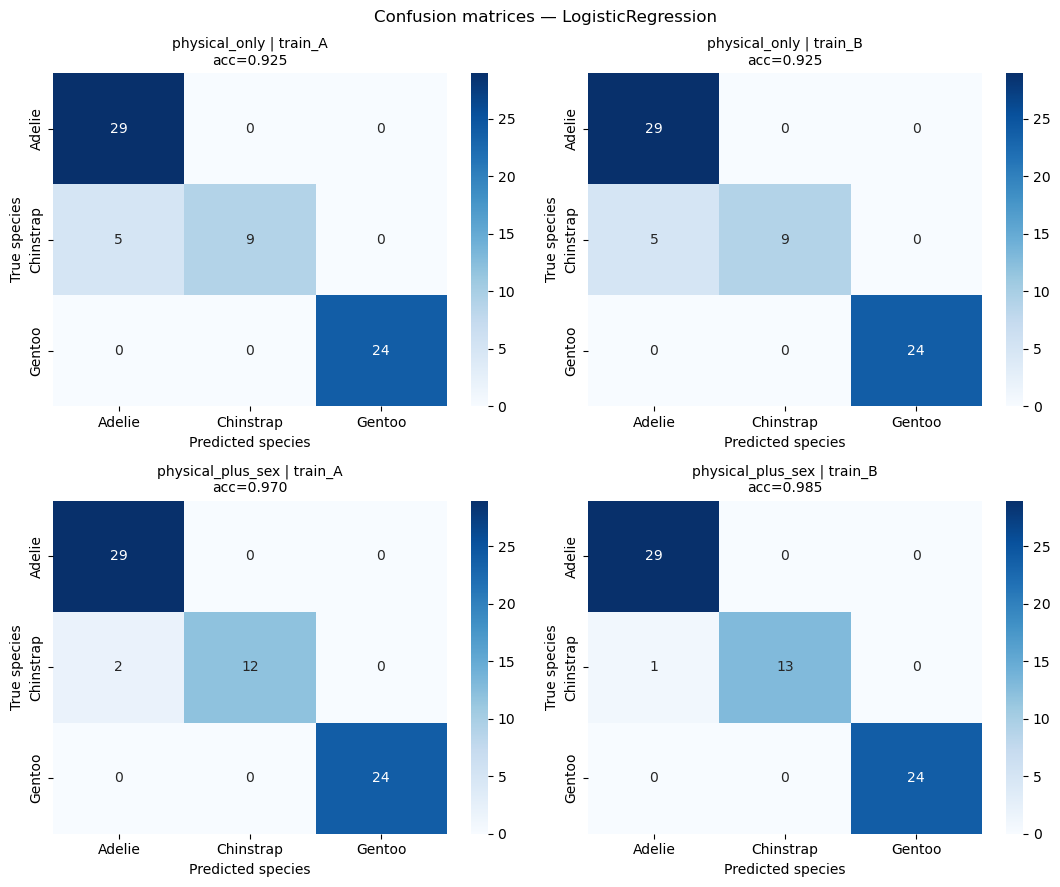

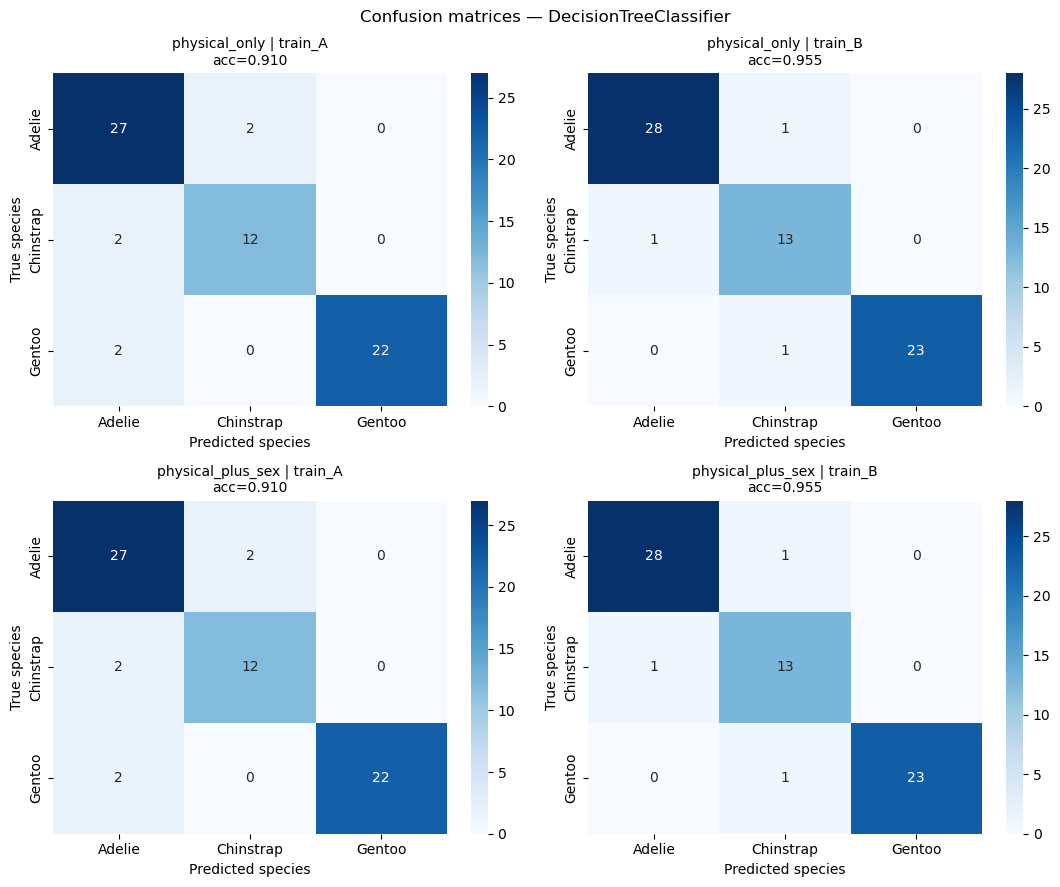

In [12]:
# --- Cell: Confusion matrices per (config, train_set) -----------------------
# For each model we draw a 2x2 grid of confusion matrices:
#   rows    -> feature configuration ("physical_only", "physical_plus_sex")
#   columns -> training subset ("train_A", "train_B")
# All panels share the SAME test set (enforced in cell 11), so differences
# between panels reflect either the feature set or the training sample, never
# a change in the evaluation data.
#
# Confusion matrices are read directly from `results` (cell 11), which stores
# them as nested lists so they survive DataFrame conversions.
#
# Why heatmaps and not a printed matrix:
# - The failure pattern across species is easier to read visually.
# - Side-by-side panels make it obvious whether adding `sex` fixes a specific
#   confusion (e.g. Chinstrap <-> Adelie) or has no effect.

CONFIG_ORDER: Final[tuple[str, ...]] = ("physical_only", "physical_plus_sex")
SUBSET_ORDER: Final[tuple[str, ...]] = ("train_A", "train_B")
MODEL_ORDER: Final[tuple[str, ...]] = (
    "LogisticRegression",
    "DecisionTreeClassifier",
)

# Index results by (model, config, train_set) for O(1) lookup while plotting.
results_index: dict[tuple[str, str, str], ClsMetrics] = {
    (r.model, r.config, r.train_set): r for r in results
}


def plot_confusion_grid(model_name: str) -> None:
    """Plot the 2x2 confusion grid for a given model."""
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for i, config in enumerate(CONFIG_ORDER):
        for j, subset in enumerate(SUBSET_ORDER):
            metrics = results_index[(model_name, config, subset)]
            ax = axes[i, j]
            sns.heatmap(
                np.asarray(metrics.confusion),
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=SPECIES_LABELS,
                yticklabels=SPECIES_LABELS,
                ax=ax,
            )
            ax.set_title(
                f"{config} | {subset}\nacc={metrics.accuracy:.3f}",
                fontsize=10,
            )
            ax.set_xlabel("Predicted species")
            ax.set_ylabel("True species")
    fig.suptitle(f"Confusion matrices — {model_name}", fontsize=12)
    plt.tight_layout()
    plt.show()


for model_name in MODEL_ORDER:
    plot_confusion_grid(model_name)

config                            physical_only  physical_plus_sex  delta_sex
model                  train_set                                             
DecisionTreeClassifier train_A           0.9104             0.9104     0.0000
                       train_B           0.9552             0.9552     0.0000
LogisticRegression     train_A           0.9254             0.9701     0.0448
                       train_B           0.9254             0.9851     0.0597


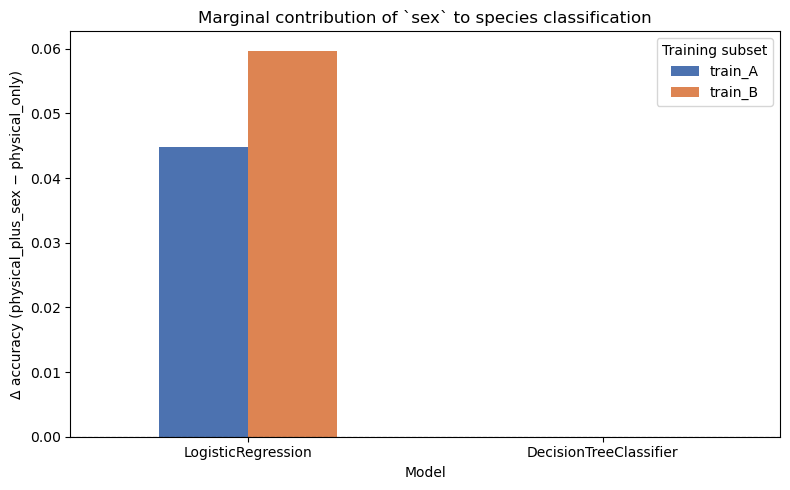

In [13]:
# --- Cell: Marginal contribution of `sex` -----------------------------------
# The core question of the study: how much does adding `sex` improve
# classification of `species`, and is that improvement stable across the two
# training subsets?
#
# For each (model, train_set) we compute:
#   delta = accuracy(physical_plus_sex) - accuracy(physical_only)
#
# Reading the result:
# - A positive and consistent delta across train_A and train_B means `sex`
#   carries signal independent of the physical traits.
# - A delta near zero means `sex` is redundant given the physical traits.
# - A delta that flips sign between train_A and train_B means the effect is
#   not robust to the training sample; the study would need a larger sample
#   or cross-validation to make a reliable claim.

wide = (
    results_df
    .pivot_table(
        index=["model", "train_set"],
        columns="config",
        values="accuracy",
    )
    .loc[:, list(CONFIG_ORDER)]
)
wide["delta_sex"] = wide["physical_plus_sex"] - wide["physical_only"]
wide = wide.round(4)

print(wide.to_string())

# --- Bar chart: delta per (model, train_set) --------------------------------
delta_pivot = (
    wide["delta_sex"]
    .unstack("train_set")
    .loc[list(MODEL_ORDER), list(SUBSET_ORDER)]
)

fig, ax = plt.subplots(figsize=(8, 5))
delta_pivot.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.axhline(0.0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Marginal contribution of `sex` to species classification")
ax.set_xlabel("Model")
ax.set_ylabel("Δ accuracy (physical_plus_sex − physical_only)")
ax.set_xticklabels(list(MODEL_ORDER), rotation=0)
ax.legend(title="Training subset")
plt.tight_layout()
plt.show()

In [14]:
# --- Cell: Decision Tree tuning per study branch ----------------------------
# GridSearchCV is executed independently for each (config, train_set) branch,
# using only the corresponding TRAINING rows for the search. The shared test
# set is NOT touched during tuning.
#
# What we are checking:
# - Whether the best hyperparameters depend on the feature set (i.e. does
#   `sex` change the optimal tree complexity?).
# - Whether they depend on the training sample (i.e. is the tuning stable
#   across train_A and train_B?).
#
# `cv=CV_FOLDS` with stratification keeps folds class-balanced; the base
# estimator fixes `random_state` so fold assignment is reproducible.
#
# The original notebook defined two GridSearchCV objects (one unused) and
# mislabeled the log messages as "Logistic Regression". Both issues are
# corrected here: a single grid per branch, and log messages that name the
# actual estimator.

PARAM_GRID: Final[dict[str, list[object]]] = {
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}


@dataclass(frozen=True)
class TuningResult:
    """Best hyperparameters and CV score for one tuning branch."""
    config: str
    train_set: str
    best_params: dict[str, object]
    best_cv_score: float


def tune_tree_on_branch(
    config_name: str,
    subset_name: str,
    features: Sequence[str],
    subset: IndexSplit,
) -> TuningResult:
    """Run GridSearchCV for the DecisionTree on a single study branch."""
    x_train, _, y_train, _ = materialize(scaled, features, subset)
    grid = GridSearchCV(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        param_grid=PARAM_GRID,
        scoring="accuracy",
        cv=CV_FOLDS,
    )
    grid.fit(x_train, y_train)
    return TuningResult(
        config=config_name,
        train_set=subset_name,
        best_params=dict(grid.best_params_),
        best_cv_score=float(grid.best_score_),
    )


tuning_results: list[TuningResult] = []
for config_name, features in STUDY_CONFIGS.items():
    for subset_name, subset in (("train_A", train_pair.a), ("train_B", train_pair.b)):
        result = tune_tree_on_branch(config_name, subset_name, features, subset)
        tuning_results.append(result)
        logger.info(
            "[%s | %s] best_params=%s | best_cv_accuracy=%.4f",
            result.config,
            result.train_set,
            result.best_params,
            result.best_cv_score,
        )

tuning_df = pd.DataFrame(
    [
        {
            "config": r.config,
            "train_set": r.train_set,
            "best_cv_accuracy": round(r.best_cv_score, 4),
            **{f"param_{k}": v for k, v in r.best_params.items()},
        }
        for r in tuning_results
    ]
)
print(tuning_df.to_string(index=False))

2026-10-09 22:32:35,435 | INFO     | [physical_only | train_A] best_params={'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5} | best_cv_accuracy=0.9402
2026-10-09 22:32:44,740 | INFO     | [physical_only | train_B] best_params={'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2} | best_cv_accuracy=0.9322
2026-10-09 22:32:50,285 | INFO     | [physical_plus_sex | train_A] best_params={'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2} | best_cv_accuracy=0.9328
2026-10-09 22:32:55,563 | INFO     | [physical_plus_sex | train_B] best_params={'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2} | best_cv_accuracy=0.9470


           config train_set  best_cv_accuracy param_max_depth  param_min_samples_leaf  param_min_samples_split
    physical_only   train_A            0.9402            None                       1                        5
    physical_only   train_B            0.9322            None                       1                        2
physical_plus_sex   train_A            0.9328            None                       1                        2
physical_plus_sex   train_B            0.9470            None                       1                        2


In [15]:
# --- Cell: Regression study — setup and training ---------------------------
# Regression target: `body_mass_g`. Same study design as classification:
#   - two feature configurations differing only by `sex`;
#   - two disjoint training subsets (A and B) sharing the SAME test set.
#
# The split indices are REUSED from the classification study (master_split
# and train_pair), so both studies see identical row partitions. Only the
# target changes, which is done by re-wrapping the index splits with a
# different `target` field. This guarantees that any difference between the
# classification and regression studies comes from the target and the model,
# never from a different random partition.
#
# Feature sets mirror the original notebook: `species` is included as a
# feature (it acts as a body-size proxy), and `body_mass_g` is the target,
# so it is excluded from the predictors. The two configurations differ
# exactly by `sex`, which is what makes the marginal contribution measurable.
#
# Two regressors are compared, matching the original notebook:
#   - LinearRegression
#   - RandomForestRegressor
# RandomForest requires a 1-D target, so `y_train` is raveled before fitting.
# The original notebook discovered this constraint at runtime; here it is
# handled explicitly and documented.

REGRESSION_TARGET: Final[str] = "body_mass_g"
REGRESSION_PHYSICAL: Final[tuple[str, ...]] = (
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
)
REGRESSION_CONFIGS: Final[dict[str, tuple[str, ...]]] = {
    "physical_only": ("species", *REGRESSION_PHYSICAL),
    "physical_plus_sex": ("species", *REGRESSION_PHYSICAL, "sex"),
}

# Re-wrap the classification index splits with the regression target. The
# row indices are identical, only the target column changes.
regression_split = IndexSplit(
    train_idx=master_split.train_idx,
    test_idx=master_split.test_idx,
    target=REGRESSION_TARGET,
)
regression_pair = TrainPair(
    a=IndexSplit(
        train_idx=train_pair.a.train_idx,
        test_idx=train_pair.a.test_idx,
        target=REGRESSION_TARGET,
    ),
    b=IndexSplit(
        train_idx=train_pair.b.train_idx,
        test_idx=train_pair.b.test_idx,
        target=REGRESSION_TARGET,
    ),
    target=REGRESSION_TARGET,
)


@dataclass(frozen=True)
class RegMetrics:
    """Metrics for one (config, train_set, model) triple on the shared test."""
    config: str
    train_set: str
    model: str
    mse: float
    mae: float
    r2: float
    rmse: float


def build_regressor(name: str) -> BaseEstimator:
    """Instantiate a regressor by name with the project's seed."""
    if name == "LinearRegression":
        return LinearRegression()
    if name == "RandomForestRegressor":
        return RandomForestRegressor(random_state=RANDOM_STATE)
    raise ValueError(f"Unknown regressor: {name!r}")


def evaluate_regressor(
    config: str,
    train_set: str,
    model: BaseEstimator,
    x_test: pd.DataFrame,
    y_test: pd.Series,
) -> RegMetrics:
    """Evaluate a fitted regressor on the shared test set."""
    y_true = np.asarray(y_test).ravel()
    y_pred = np.asarray(model.predict(x_test)).ravel()
    mse = float(mean_squared_error(y_true, y_pred))
    return RegMetrics(
        config=config,
        train_set=train_set,
        model=type(model).__name__,
        mse=mse,
        mae=float(mean_absolute_error(y_true, y_pred)),
        r2=float(r2_score(y_true, y_pred)),
        rmse=float(np.sqrt(mse)),
    )


reg_results: list[RegMetrics] = []
for config_name, features in REGRESSION_CONFIGS.items():
    for subset_name, subset in (
        ("train_A", regression_pair.a),
        ("train_B", regression_pair.b),
    ):
        x_train, x_test, y_train, y_test = materialize(scaled, features, subset)
        for model_name in ("LinearRegression", "RandomForestRegressor"):
            model = build_regressor(model_name)
            # RandomForest requires a 1-D target; ravel is safe for both.
            model.fit(x_train, np.asarray(y_train).ravel())
            reg_results.append(
                evaluate_regressor(config_name, subset_name, model, x_test, y_test)
            )

reg_results_df = pd.DataFrame([r.__dict__ for r in reg_results])
print(
    reg_results_df[
        ["config", "train_set", "model", "mse", "mae", "r2", "rmse"]
    ]
    .sort_values(["config", "train_set", "model"])
    .round(4)
    .to_string(index=False)
)

           config train_set                 model    mse    mae     r2   rmse
    physical_only   train_A      LinearRegression 0.0135 0.0941 0.7120 0.1163
    physical_only   train_A RandomForestRegressor 0.0115 0.0833 0.7561 0.1071
    physical_only   train_B      LinearRegression 0.0136 0.0942 0.7114 0.1165
    physical_only   train_B RandomForestRegressor 0.0097 0.0768 0.7931 0.0986
physical_plus_sex   train_A      LinearRegression 0.0108 0.0880 0.7696 0.1040
physical_plus_sex   train_A RandomForestRegressor 0.0091 0.0749 0.8056 0.0956
physical_plus_sex   train_B      LinearRegression 0.0100 0.0813 0.7862 0.1002
physical_plus_sex   train_B RandomForestRegressor 0.0075 0.0670 0.8406 0.0865


R² by branch (delta = marginal contribution of `sex`)
config                           physical_only  physical_plus_sex  delta_r2
model                 train_set                                            
LinearRegression      train_A           0.7120             0.7696    0.0576
                      train_B           0.7114             0.7862    0.0748
RandomForestRegressor train_A           0.7561             0.8056    0.0495
                      train_B           0.7931             0.8406    0.0475

RMSE by branch (delta = marginal contribution of `sex`)
config                           physical_only  physical_plus_sex  delta_rmse
model                 train_set                                              
LinearRegression      train_A             0.12               0.10       -0.01
                      train_B             0.12               0.10       -0.02
RandomForestRegressor train_A             0.11               0.10       -0.01
                      train_B             0

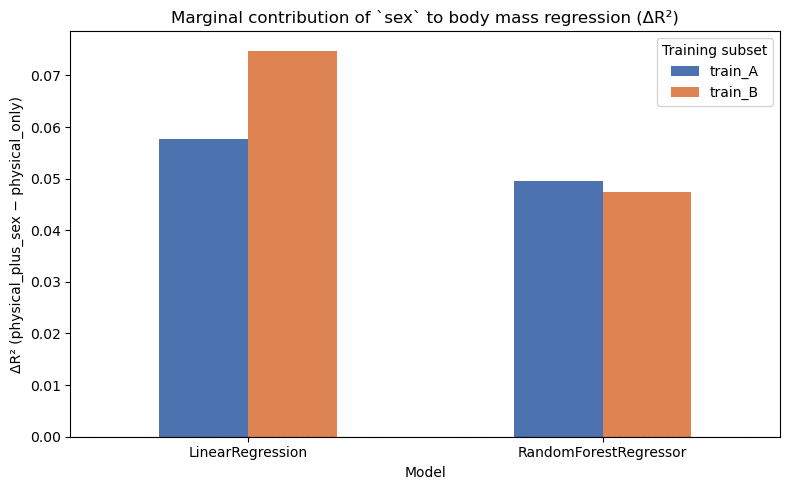

In [16]:
# --- Cell: Marginal contribution of `sex` in regression --------------------
# Symmetric to the classification delta analysis. For each (model, train_set)
# we compute the change in test metrics when `sex` is added on top of the
# physical predictors.
#
# Reported deltas:
#   ΔR²   = R²(physical_plus_sex) − R²(physical_only)      -> higher is better
#   ΔRMSE = RMSE(physical_plus_sex) − RMSE(physical_only)  -> lower  is better
#
# A positive ΔR² paired with a negative ΔRMSE is the consistent signal that
# `sex` adds predictive value for body mass beyond physical traits.
#
# Stability check: the SIGN of the delta should agree between train_A and
# train_B. Magnitudes may differ, but a sign flip would indicate the effect
# is not robust to the training sample.

REG_MODEL_ORDER: Final[tuple[str, ...]] = (
    "LinearRegression",
    "RandomForestRegressor",
)

reg_wide_r2 = (
    reg_results_df
    .pivot_table(
        index=["model", "train_set"],
        columns="config",
        values="r2",
    )
    .loc[:, list(CONFIG_ORDER)]
)
reg_wide_r2["delta_r2"] = (
    reg_wide_r2["physical_plus_sex"] - reg_wide_r2["physical_only"]
)
reg_wide_r2 = reg_wide_r2.round(4)
print("R² by branch (delta = marginal contribution of `sex`)")
print(reg_wide_r2.to_string())

reg_wide_rmse = (
    reg_results_df
    .pivot_table(
        index=["model", "train_set"],
        columns="config",
        values="rmse",
    )
    .loc[:, list(CONFIG_ORDER)]
)
reg_wide_rmse["delta_rmse"] = (
    reg_wide_rmse["physical_plus_sex"] - reg_wide_rmse["physical_only"]
)
reg_wide_rmse = reg_wide_rmse.round(2)
print("\nRMSE by branch (delta = marginal contribution of `sex`)")
print(reg_wide_rmse.to_string())

# --- Bar chart of ΔR² per (model, train_set) --------------------------------
delta_r2_pivot = (
    reg_wide_r2["delta_r2"]
    .unstack("train_set")
    .loc[list(REG_MODEL_ORDER), list(SUBSET_ORDER)]
)

fig, ax = plt.subplots(figsize=(8, 5))
delta_r2_pivot.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.axhline(0.0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Marginal contribution of `sex` to body mass regression (ΔR²)")
ax.set_xlabel("Model")
ax.set_ylabel("ΔR² (physical_plus_sex − physical_only)")
ax.set_xticklabels(list(REG_MODEL_ORDER), rotation=0)
ax.legend(title="Training subset")
plt.tight_layout()
plt.show()

In [ ]:
# --- Cell: Study synthesis and artifact export ------------------------------
# Final summary of the two studies. Two questions are answered:
#
#   Q1 (classification): does `sex` add signal on top of physical traits
#       when predicting `species`, and is that gain stable across train_A
#       and train_B?
#
#   Q2 (regression): does `sex` add signal on top of physical traits when
#       predicting `body_mass_g`, with the same stability requirement?
#
# A finding is considered ROBUST when the sign of the delta agrees between
# train_A and train_B. Magnitudes may differ between subsets; the direction
# should not.
#
# All result tables are exported to `artifacts/` so the run is auditable.
# The directory is created with pathlib (no os.path), and the export uses
# the DataFrame objects already materialized in previous cells.

from pathlib import Path

# ARTIFACTS_DIR: Final[Path] = Path("artifacts")
# ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# --- Classification summary -------------------------------------------------
cls_summary = (
    results_df
    .pivot_table(
        index=["model", "train_set"],
        columns="config",
        values="accuracy",
    )
    .loc[:, list(CONFIG_ORDER)]
)
cls_summary["delta_sex"] = (
    cls_summary["physical_plus_sex"] - cls_summary["physical_only"]
)
cls_summary["sign_stable"] = cls_summary.groupby("model")["delta_sex"].transform(
    lambda s: bool((s > 0).all() or (s < 0).all())
)
cls_summary = cls_summary.round(4)
print("Classification summary (accuracy and marginal effect of `sex`):")
print(cls_summary.to_string())

# --- Regression summary -----------------------------------------------------
reg_summary = reg_wide_r2.copy()
reg_summary["sign_stable"] = reg_summary.groupby("model")["delta_r2"].transform(
    lambda s: bool((s > 0).all() or (s < 0).all())
)
print("\nRegression summary (R² and marginal effect of `sex`):")
print(reg_summary.to_string())

# --- Export -----------------------------------------------------------------
#results_df.to_csv(
#    ARTIFACTS_DIR / "classification_results.csv", index=False
#)
#reg_results_df.to_csv(
#    ARTIFACTS_DIR / "regression_results.csv", index=False
#)
#tuning_df.to_csv(
#    ARTIFACTS_DIR / "decision_tree_tuning.csv", index=False
#)
#cls_summary.to_csv(ARTIFACTS_DIR / "classification_summary.csv")
#reg_summary.to_csv(ARTIFACTS_DIR / "regression_summary.csv")

#logger.info("Artifacts written to: %s", ARTIFACTS_DIR.resolve())
#logger.info("Notebook complete.")

Classification summary (accuracy and marginal effect of `sex`):
config                            physical_only  physical_plus_sex  delta_sex  sign_stable
model                  train_set                                                          
DecisionTreeClassifier train_A           0.9104             0.9104     0.0000        False
                       train_B           0.9552             0.9552     0.0000        False
LogisticRegression     train_A           0.9254             0.9701     0.0448         True
                       train_B           0.9254             0.9851     0.0597         True

Regression summary (R² and marginal effect of `sex`):
config                           physical_only  physical_plus_sex  delta_r2  sign_stable
model                 train_set                                                         
LinearRegression      train_A           0.7120             0.7696    0.0576         True
                      train_B           0.7114             0.7862   

In [18]:
# --- Cell: Individual confusion matrices for the report ---------------------
# One PNG per (model, config, train_set) combination. Used in the classification
# and regression sections to show a single model's behavior.
from pathlib import Path

FIGURES_DIR = Path("docs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for (model_name, config_name, subset_name), metrics in results_index.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        np.asarray(metrics.confusion),
        annot=True, fmt="d", cmap="Blues",
        xticklabels=SPECIES_LABELS, yticklabels=SPECIES_LABELS,
        ax=ax,
    )
    ax.set_title(f"{model_name} | {config_name} | {subset_name}")
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("True species")
    plt.tight_layout()
    fig.savefig(
        FIGURES_DIR / f"cm_{model_name}_{config_name}_{subset_name}.png",
        dpi=150,
    )
    plt.close(fig)

In [19]:
# --- Cell: 2x2 confusion grid with gender-first titles ----------------------
# Same data as the notebook's grid, but with titles that emphasize the gender
# axis (rows) over the A/B axis (columns). Used in the robustness section.
for model_name in MODEL_ORDER:
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for i, config in enumerate(CONFIG_ORDER):
        for j, subset in enumerate(SUBSET_ORDER):
            metrics = results_index[(model_name, config, subset)]
            ax = axes[i, j]
            sns.heatmap(
                np.asarray(metrics.confusion),
                annot=True, fmt="d", cmap="Blues",
                xticklabels=SPECIES_LABELS, yticklabels=SPECIES_LABELS,
                ax=ax,
            )
            config_label = "With sex" if config == "physical_plus_sex" else "Without sex"
            ax.set_title(
                f"{config_label} | {subset}\nacc={metrics.accuracy:.3f}",
                fontsize=10,
            )
            ax.set_xlabel("Predicted species")
            ax.set_ylabel("True species")
    fig.suptitle(f"Confusion matrices — {model_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(FIGURES_DIR / f"grid_{model_name}.png", dpi=150)
    plt.close(fig)